In [5]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t

from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, LogisticRegression
from sklearn.metrics import balanced_accuracy_score, mean_absolute_error
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [3]:
plt.rcParams.update({
    "font.family": "serif",
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.title_fontsize": 12,
    "legend.fontsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "lines.linewidth": 2,
    "lines.markersize": 6,
    "legend.frameon": False,
    "figure.figsize": (9, 3)  # standard size for subplots
})
COLORS = ['#5F6F52', '#A9B388', '#B99470']
COLORS2 = ['#395144', '#4E6C50', '#AA8B56']

In [4]:
SEED = 2210
WEATHER = ["MnDir(degT)", "MnSpd(mps)", "MnTemp(C)", "MnRH(%)",
           "Rain(mm)", "RadGlb(MJ/m2)", "Average W/m2", "Predicted BGT",
           "THI", "HLI", "Grazing HLI2"]
STATIC = ["NZDI", "Transport distance (calculated)",
          "lairage time (calculated)", "Age"]
TARGETS = ["live weight", "carcass weight", "price", "Total number of defects"]
BANDS = [(1, 4), (5, 10), (11, 20), (21, 30), (31, 60), (61, 90), (91, 120)]


In [6]:
beef = pd.read_csv("data/beef_preprocessed.csv")
beef.groupby("Animal Type").agg(
    animals=("kill date", "size"),
    slaughter_dates=("kill date", "nunique")
)

,animals,slaughter_dates
Animal Type,,
cow,46,3
heifer,233,18
steer,594,33


In [8]:
# assign whole slaughter groups to approximately balanced folds
n_folds = 10
fold_map = {}

for animal in ["steer", "heifer"]:
    counts = (beef.loc[beef["Animal Type"].eq(animal)]
              .groupby("kill date").size().sort_values(ascending=False))
    sizes = np.zeros(n_folds, dtype=int)

    for date, count in counts.items():
        fold = sizes.argmin()
        fold_map[animal, date] = fold + 1
        sizes[fold] += count

fold_map = (pd.Series(fold_map, name="fold")
            .rename_axis(["Animal Type", "kill date"]).reset_index())

# attach the mapping and exclude cows
data = beef.loc[beef["Animal Type"].isin(["steer", "heifer"])].merge(
    fold_map, on=["Animal Type", "kill date"]
)

# inspect animal counts and slaughter dates per fold
fold_sizes = data.groupby(["fold", "Animal Type"]).agg(
    animals=("kill date", "size"),
    slaughter_dates=("kill date", "nunique")
)
display(fold_sizes.unstack("Animal Type"))

animals       slaughter_dates      
Animal Type  heifer steer          heifer steer
fold                                           
1                32    61               1     3
2                29    60               1     3
3                24    60               2     3
4                21    60               2     3
5                22    56               2     2
6                21    59               2     3
7                20    59               2     4
8                23    59               2     4
9                21    60               2     4
10               20    60               2     4

In [10]:
from sklearn.model_selection import GroupKFold

for n_inner in [3, 5]:
    failures = []
    for animal in ["steer", "heifer"]:
        sub = data.loc[data["Animal Type"].eq(animal)].dropna(
            subset=["Total number of defects"])

        for outer_fold in sorted(sub["fold"].unique()):
            train = sub.loc[sub["fold"].ne(outer_fold)]
            y = train["Total number of defects"].gt(0)

            # check the same grouped splits that will be used for tuning
            cv = GroupKFold(n_inner, shuffle=True, random_state=SEED)
            for inner_fold, (tr, val) in enumerate(
                cv.split(train, y, groups=train["kill date"]), 1
            ):
                if y.iloc[tr].nunique() < 2 or y.iloc[val].nunique() < 2:
                    failures.append(f"{animal}: outer {outer_fold}, inner {inner_fold}")

    print(f"{n_inner} inner folds: " + (
        "both classes present in every training and validation split."
        if not failures else "single-class splits: " + "; ".join(failures)
    ))

3 inner folds: both classes present in every training and validation split.
5 inner folds: both classes present in every training and validation split.


# Set up experiments

In [1]:
def prepare_data():
    beef = pd.read_csv("data/beef_preprocessed.csv")
    old = pd.read_csv("data/beef_weather_windows.csv")
    weather = pd.read_csv("data/weather_preprocessed.csv", low_memory=False)

    # keep animals at least 120 days old; preserve indices for the window join
    beef = beef.loc[beef["Age"] * 30 >= 120].copy()

    # reproduce window preprocessing for the new windows
    beef["kill date"] = pd.to_datetime(beef["kill date"])
    weather["date"] = pd.to_datetime(weather["Date(NZST)"])

    # match the previous fixed, whole-weather-series thresholds
    thresholds = weather[WEATHER[1:]].quantile(0.9)
    additions = []
    for date in beef["kill date"].sort_values().unique():
        feats = {"kill date": date}
        for lo, hi in BANDS:
            if hi <= 60:
                continue
            sub = weather.loc[weather["date"].between(
                date - pd.Timedelta(days=hi), date - pd.Timedelta(days=lo))]

            for col in WEATHER:
                values = sub[col].dropna()
                prefix = f"{col}__win{lo}_{hi}_"
                stats = {"max": values.max(), "min": values.min(), "diff": values.max() - values.min(),
                    "mean": values.mean(), "std": values.std(ddof=0)}
                
                feats.update({prefix + k: v for k, v in stats.items()})
                if col in thresholds:
                    thr = thresholds[col]
                    feats[prefix + f"above{round(thr, 2)}_count"] = (
                        (values > thr).sum() if len(values) else np.nan)
        additions.append(feats)

    extra = pd.DataFrame(additions).set_index("kill date")
    data = beef.join(old).join(extra, on="kill date")
    base = STATIC + [c for c in old if "__win" in c]
    feature_sets = {
        60: base,
        90: base + [c for c in extra if "__win61_90_" in c],
        120: base + list(extra.columns),
    }
    return data, feature_sets

In [ ]:
def fit_horizons(data, feature_sets, targets=TARGETS, animal_types=("steer", "heifer"),
                 outer_folds=5, inner_folds=3, n_jobs=2):
    rows, predictions, samples = [], [], []
    for animal in animal_types:
        for target in targets:
            subset = data.loc[data["Animal Type"].eq(animal) & data[target].notna()]
            groups = subset["kill date"]
            classification = target == "Total number of defects"
            y = (subset[target] > 0).astype(int) if classification else subset[target]
            info = {"animal_type": animal, "target": target}
            samples.append({**info, "included_animals": len(subset), "included_dates": groups.nunique()})

            # use elastic-net regression or its binary classification counterpart
            if classification:
                model = LogisticRegression(penalty="elasticnet", solver="saga",
                                           class_weight="balanced", max_iter=20000, random_state=SEED)
                grid = {"model__C": [0.01, 0.1, 1, 10], "model__l1_ratio": [0.1, 0.5, 0.9]}
                scoring, metric, evaluate = "balanced_accuracy", "Balanced accuracy", balanced_accuracy_score
            else:
                model = ElasticNet(max_iter=50000, random_state=SEED)
                grid = {"model__alpha": [0.01, 0.1, 1, 10], "model__l1_ratio": [0.1, 0.5, 0.9]}
                scoring, metric, evaluate = "neg_mean_absolute_error", "MAE", mean_absolute_error

            pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
                ("scaler", StandardScaler()), ("model", model)
            ])

            # hold out whole slaughter dates; use identical folds for every horizon
            outer = GroupKFold(outer_folds, shuffle=True, random_state=SEED)
            for fold, (train, test) in enumerate(outer.split(subset, y, groups), 1):
                y_train, y_test = y.iloc[train], y.iloc[test]
                inner = list(GroupKFold(inner_folds, shuffle=True, random_state=SEED).split(
                    subset.iloc[train], y_train, groups.iloc[train]))

                # both classes are needed for comparable balanced accuracy
                if classification and (
                    y_test.nunique() < 2 or
                    any(y_train.iloc[idx].nunique() < 2 for pair in inner for idx in pair)
                ):
                    raise ValueError(f"Single-class fold: {animal}, {target}, fold {fold}")

                for horizon, columns in feature_sets.items():
                    X = subset[columns]

                    # tune and preprocess using only the outer training data
                    search = GridSearchCV(pipeline, grid, scoring=scoring, cv=inner,
                                          n_jobs=n_jobs, error_score="raise")
                    search.fit(X.iloc[train], y_train)
                    pred = search.predict(X.iloc[test])
                    score = evaluate(y_test, pred)
                    run = {**info, "fold": fold, "horizon": horizon}
                    rows.append({
                        **run, "metric": metric, "score": score,
                        "n_train": len(train), "n_test": len(test), "n_features": len(columns),
                        "n_train_dates": groups.iloc[train].nunique(),
                        "n_test_dates": groups.iloc[test].nunique(), "n_dates": groups.nunique(),
                        "best_params": str(search.best_params_)
                    })
                    predictions.extend(
                        {**run, "animal_index": idx, "kill_date": groups.loc[idx],
                         "observed": obs, "predicted": fitted}
                        for idx, obs, fitted in zip(subset.index[test], y_test, pred)
                    )
                    print(f"{animal} | {target} | fold {fold} | {horizon} days: {score:.4f}")

    return pd.DataFrame(rows), pd.DataFrame(predictions), pd.DataFrame(samples)

# Run experiments

In [ ]:
# data, feature_sets, coverage = prepare_data(min_coverage=0.90)
# scores, predictions, samples = fit_horizons(data, feature_sets, n_jobs=2)
# scores.to_csv("results/cv_results_weather_horizons.csv", index=False)

# Present results

Same animals and slaughter-date folds for 60, 90 and 120 days. Coverage retained 467 steers (457 for price) across 21 dates. Heifers had only four eligible dates and were skipped. Existing preprocessing and positional animal/window alignment are retained.

Ranks are descriptive, not autorank CD significance tests. Intervals use an approximate CV variance correction based on date counts, with Bonferroni adjustment across eight comparisons; p-values use Holm adjustment. Inconclusive does not mean equivalent.

In [ ]:
df_res = pd.read_csv("results/cv_results_weather_horizons.csv")

rows = []
for (atype, target, metric), sub in df_res.groupby(["animal_type", "target", "metric"]):
    tab = sub.pivot(index="fold", columns="horizon", values="score")
    fold_sizes = sub[sub["horizon"].eq(60)].set_index("fold").loc[tab.index]
    ratio = (fold_sizes["n_test_dates"] / fold_sizes["n_train_dates"]).mean()

    for horizon in [90, 120]:
        gain = tab[60] - tab[horizon] if metric == "MAE" else tab[horizon] - tab[60]
        se = np.sqrt((1 / len(gain) + ratio) * gain.var(ddof=1))
        p = 2 * t.sf(abs(gain.mean() / se), len(gain) - 1) if se > 0 else 1.0
        rows.append({"animal_type": atype, "target": target, "metric": metric,
                     "horizon": horizon, "improvement": gain.mean(), "se": se,
                     "df": len(gain) - 1, "pvalue": p})

comparison = pd.DataFrame(rows)
m = len(comparison)
order = np.argsort(comparison["pvalue"].to_numpy())
adjusted = np.empty(m)
adjusted[order] = np.minimum(1, np.maximum.accumulate(
    comparison["pvalue"].to_numpy()[order] * np.arange(m, 0, -1)))
comparison["p_holm"] = adjusted
half_width = t.ppf(1 - 0.05 / (2 * m), comparison["df"]) * comparison["se"]
comparison["lower"] = comparison["improvement"] - half_width
comparison["upper"] = comparison["improvement"] + half_width
comparison.loc[comparison["se"].eq(0), ["lower", "upper"]] = [-np.inf, np.inf]
comparison.to_csv("results/weather_horizon_comparisons.csv", index=False)

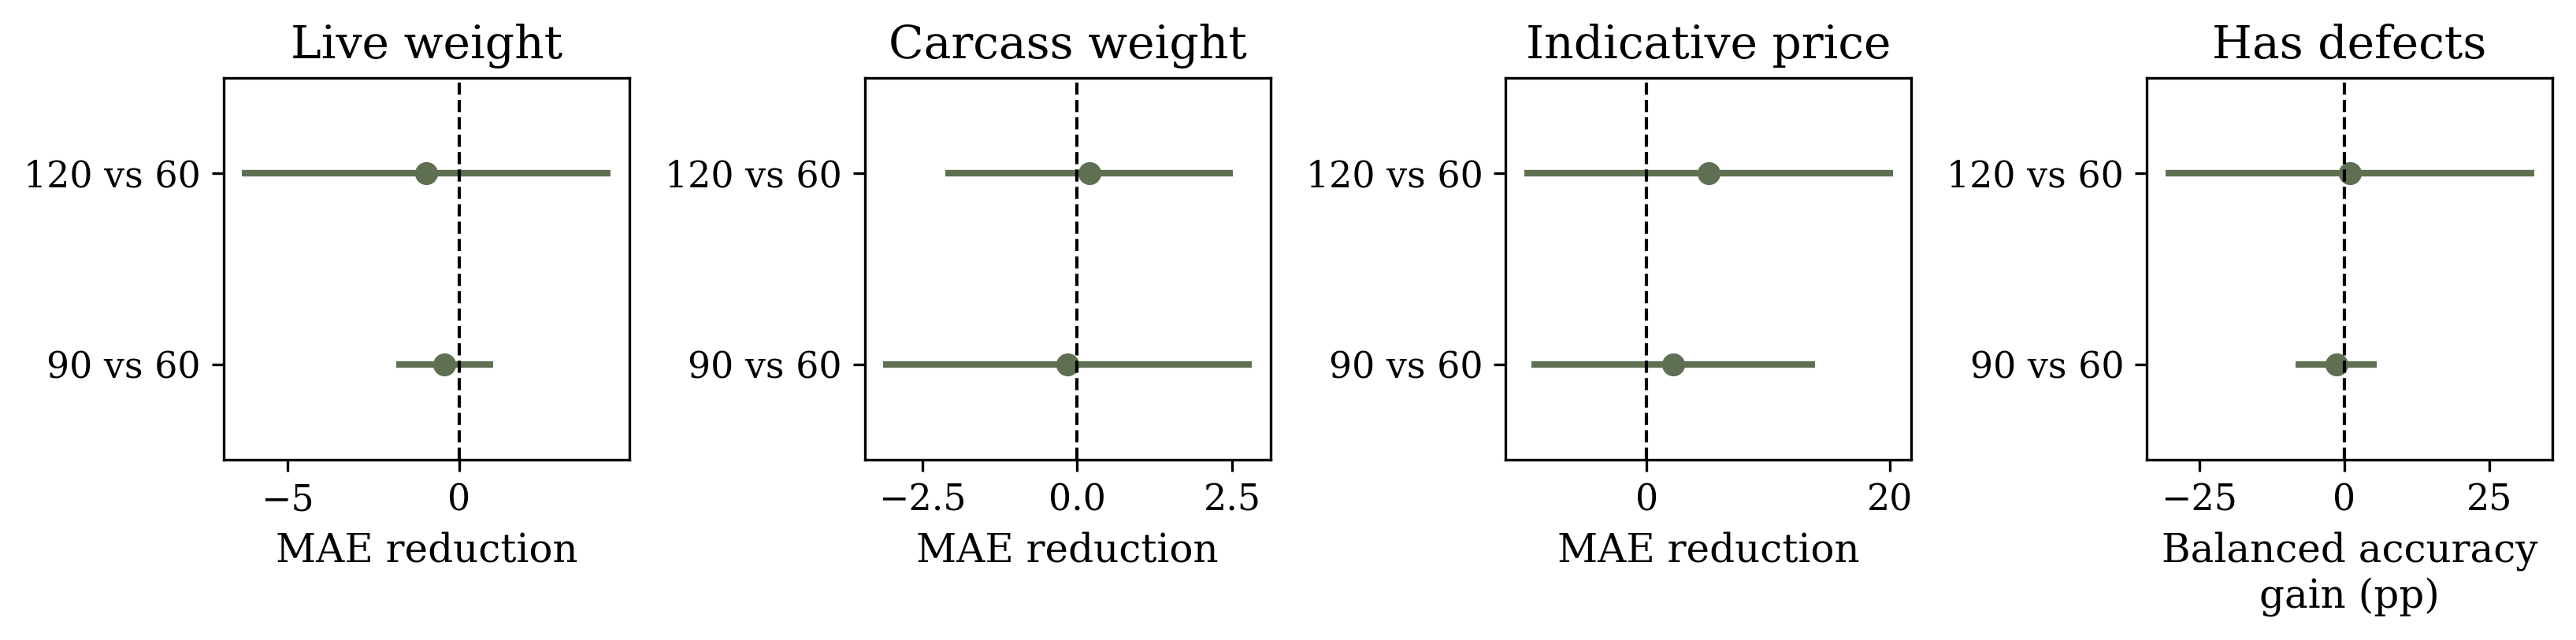

In [ ]:
# comparison intervals: positive values favour longer weather history
animal_types = df_res["animal_type"].unique()
target_order = ["live weight", "carcass weight", "price", "Total number of defects"]

fig, axes = plt.subplots(len(animal_types), 4, figsize=(11, 2.8 * len(animal_types)), squeeze=False)

for i, atype in enumerate(animal_types):
    for ax, target in zip(axes[i], target_order):
        sub = comparison[comparison["animal_type"].eq(atype) & comparison["target"].eq(target)].sort_values("horizon")
        if sub.empty:
            ax.axis("off")
            continue
        scale = 100 if target == "Total number of defects" else 1
        for j, (_, row) in enumerate(sub.iterrows()):
            ax.plot(row["improvement"] * scale, j, "o", color=COLORS[0])
            if np.isfinite([row["lower"], row["upper"]]).all():
                ax.hlines(j, row["lower"] * scale, row["upper"] * scale, color=COLORS[0], linewidth=2)
        ax.axvline(0, color="black", linestyle="--", linewidth=1)
        ax.set_yticks([0, 1], ["90 vs 60", "120 vs 60"])
        ax.set_ylim(-0.5, 1.5)
        title = {"price": "Indicative price", "Total number of defects": "Has defects"}.get(target, target.capitalize())
        ax.set_title(title)
        ax.set_xlabel("Balanced accuracy\ngain (pp)" if scale == 100 else "MAE reduction")

plt.tight_layout()
plt.savefig("figs/meat_weather_horizon_intervals.svg", bbox_inches="tight")
plt.savefig("figs/meat_weather_horizon_intervals.png", dpi=300, bbox_inches="tight")
plt.show()